# Trustworthy AI — Weeks 10–11
## Model Uncertainty

**A hands-on companion notebook to the lecture (Parts 1 & 2 combined).**

A trustworthy model should know *when it doesn't know*. This notebook turns the two uncertainty
decks into small, runnable experiments: how to quantify uncertainty, how to learn it, how it
behaves on out-of-distribution data, and how it shows up in generative models.

Each section states the slide idea, then demonstrates it with a *tiny, self-contained* model so
everything runs in a few seconds on a free Colab GPU.

> **How to use:** `Runtime → Run all`, or run section by section. The **Setup** cells must run
> first.

---

### Roadmap

**Part 1 — Quantifying & Learning Uncertainty (W10)**
1. Aleatoric vs. Epistemic Uncertainty (the core distinction)
2. Predictive Distribution & Confidence Intervals
3. MC Dropout
4. Deep Ensembles
5. Bayesian Neural Network (variational)
6. Evidential Deep Learning
7. Gaussian Process
8. Test-Time Data Augmentation (TTDA)
9. Entropy & OOD Detection (MNIST → Fashion-MNIST)
10. Calibration & Temperature Scaling + Reject Option

**Part 2 — Uncertainty in Generative AI & Applications (W11)**
11. Sampling Uncertainty in Text Generation (top-k / top-p / temperature)
12. Token Entropy as a Hallucination Signal
13. Self-Consistency
14. Real-World Reject-to-Human (medical-style)

---
*Companion to `W10_ModelUncertainty` and `W11_ModelUncertainty_part2`. Educational; all models
are toy models we train ourselves so everything is fast and reproducible.*

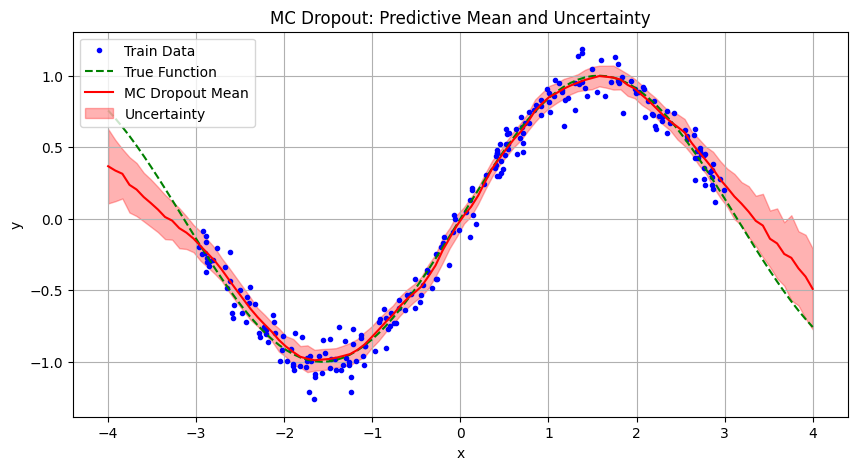

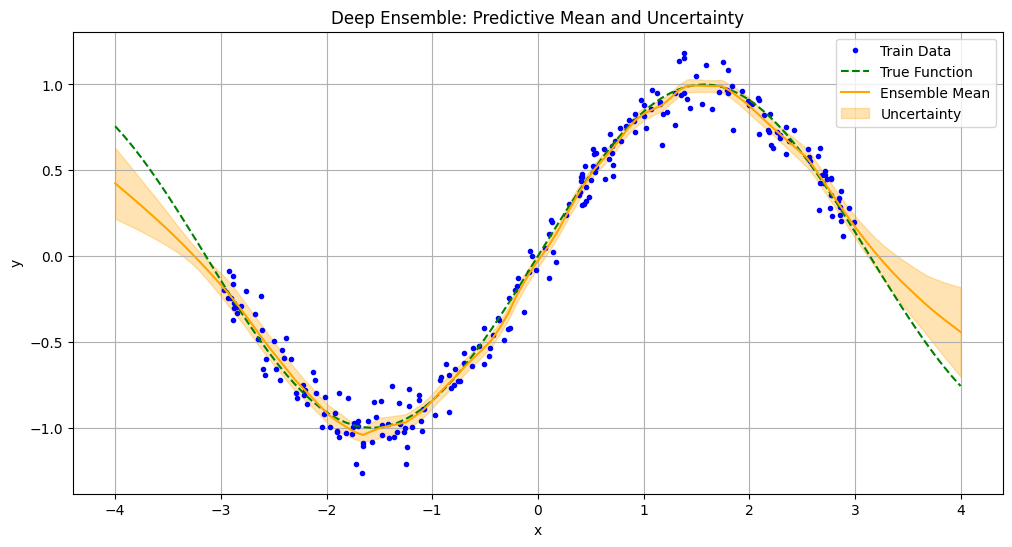

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split

# Generate synthetic data: y = sin(x) + noise
np.random.seed(0)
X = np.random.uniform(-3, 3, size=(300, 1))
y = np.sin(X) + 0.1 * np.random.randn(*X.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Convert to torch tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)


# Define a simple MLP with Dropout
class MCDropoutModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(1, 100)
        self.dropout = nn.Dropout(0.1)
        self.fc2 = nn.Linear(100, 100)
        self.fc3 = nn.Linear(100, 1)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.dropout(x)  # dropout is active during inference too
        x = F.relu(self.fc2(x))
        return self.fc3(x)


def train_model(model, X, y, epochs=500):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    loss_fn = nn.MSELoss()
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        output = model(X)
        loss = loss_fn(output, y)
        loss.backward()
        optimizer.step()


# Train MC Dropout model
mc_model = MCDropoutModel()
train_model(mc_model, X_train_t, y_train_t)

# Enable dropout during inference
mc_model.train()


# MC sampling
def predict_mc(model, X, n_samples=100):
    preds = []
    with torch.no_grad():
        for _ in range(n_samples):
            preds.append(model(X).cpu().numpy())
    return np.stack(preds)


# Predict on test input
x_plot = np.linspace(-4, 4, 100).reshape(-1, 1)
x_plot_t = torch.tensor(x_plot, dtype=torch.float32)
mc_preds = predict_mc(mc_model, x_plot_t, n_samples=100)

# Plot
mean_preds = mc_preds.mean(axis=0).squeeze()
std_preds = mc_preds.std(axis=0).squeeze()

plt.figure(figsize=(10, 5))
plt.plot(X_train, y_train, 'b.', label='Train Data')
plt.plot(x_plot, np.sin(x_plot), 'g--', label='True Function')
plt.plot(x_plot, mean_preds, 'r', label='MC Dropout Mean')
plt.fill_between(x_plot.squeeze(), mean_preds - 2 * std_preds, mean_preds + 2 * std_preds, color='r', alpha=0.3,
                 label='Uncertainty')
plt.legend()
plt.title("MC Dropout: Predictive Mean and Uncertainty")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.show()


# Define a simple MLP (no dropout)
class EnsembleModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 100),
            nn.ReLU(),
            nn.Linear(100, 100),
            nn.ReLU(),
            nn.Linear(100, 1)
        )

    def forward(self, x):
        return self.net(x)


# Train multiple models
def train_ensemble(n_models, X_train, y_train, epochs=500):
    ensemble = []
    for i in range(n_models):
        model = EnsembleModel()
        train_model(model, X_train, y_train, epochs=epochs)
        ensemble.append(model)
    return ensemble


# Train 5 models for the ensemble
ensemble_models = train_ensemble(5, X_train_t, y_train_t)


# Predict using ensemble
def predict_ensemble(models, X):
    preds = []
    with torch.no_grad():
        for model in models:
            model.eval()
            preds.append(model(X).cpu().numpy())
    return np.stack(preds)


ensemble_preds = predict_ensemble(ensemble_models, x_plot_t)

# Mean and uncertainty (std deviation across models)
ensemble_mean = ensemble_preds.mean(axis=0).squeeze()
ensemble_std = ensemble_preds.std(axis=0).squeeze()

# Plot comparison
plt.figure(figsize=(12, 6))
plt.plot(X_train, y_train, 'b.', label='Train Data')
plt.plot(x_plot, np.sin(x_plot), 'g--', label='True Function')
plt.plot(x_plot, ensemble_mean, 'orange', label='Ensemble Mean')
plt.fill_between(x_plot.squeeze(), ensemble_mean - 2 * ensemble_std, ensemble_mean + 2 * ensemble_std,
                 color='orange', alpha=0.3, label='Uncertainty')
plt.legend()
plt.title("Deep Ensemble: Predictive Mean and Uncertainty")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.show()


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Promting...

--- Sample 1 ---
Temp=0.7 | Top-k=2 | Top-p=1.0
In the future, artificial intelligence will be able to do more than just read and understand human speech, but also understand and understand the world around us. It will also be able to understand the world around us in ways that are far more complex and complex

--- Sample 2 ---
Temp=0.7 | Top-k=2 | Top-p=1.0
In the future, artificial intelligence will be able to do more than just read and write, it will be able to do more than just read and write.

In the future, artificial intelligence will be able to do more than just read and write

--- Sample 3 ---
Temp=0.7 | Top-k=2 | Top-p=1.0
In the future, artificial intelligence will be able to learn from the past, and will be able to adapt to the present.

"The future is going to be very different from the present," he said.

The research is published in

--- Sample 4 ---
Temp=0.7 | Top-k=2 | Top-p=1.0
In the future, artificial intelligence will be able to do things like make peo

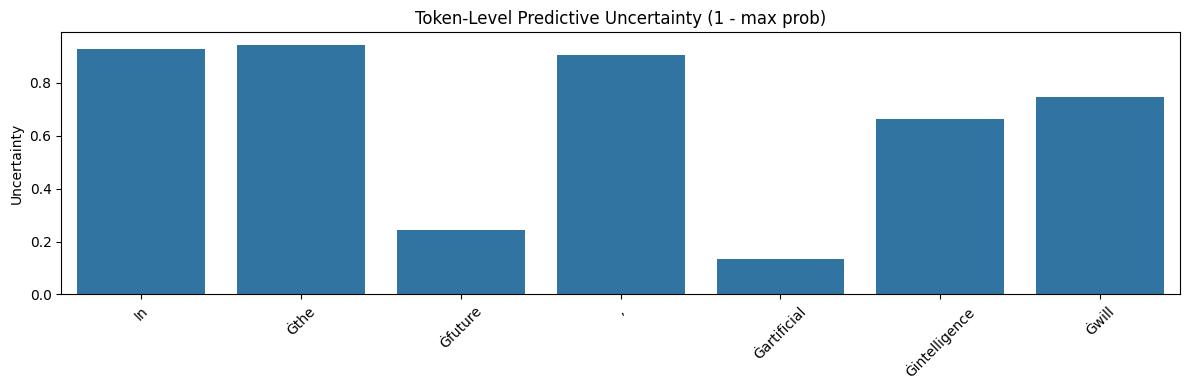

In [5]:

from transformers import GPT2LMHeadModel, GPT2Tokenizer
import torch
import matplotlib.pyplot as plt
import seaborn as sns

# Load pretrained GPT-2
model_name = "gpt2"
tokenizer = GPT2Tokenizer.from_pretrained(model_name)
model = GPT2LMHeadModel.from_pretrained(model_name)
model.eval()

if torch.cuda.is_available():
    model.cuda()
print("Promting...")
# Prompt
prompt = "In the future, artificial intelligence will"

# Encode input
input_ids = tokenizer.encode(prompt, return_tensors="pt")
if torch.cuda.is_available():
    input_ids = input_ids.cuda()

###


def generate_text(temperature=1.0, top_k=0, top_p=1.0):
    with torch.no_grad():
        output = model.generate(
            input_ids,
            max_length=50,
            temperature=temperature,
            top_k=top_k,
            top_p=top_p,
            do_sample=True,
            pad_token_id=tokenizer.eos_token_id
        )
    return tokenizer.decode(output[0], skip_special_tokens=True)



settings = [
    {"temperature": 0.7, "top_k": 2, "top_p": 1.0},
    {"temperature": 0.7, "top_k": 2, "top_p": 1.0},
    {"temperature": 0.7, "top_k": 2, "top_p": 1.0},
    {"temperature": 0.7, "top_k": 2, "top_p": 1.0},
]

for i, s in enumerate(settings):
    print(f"\n--- Sample {i+1} ---")
    print(f"Temp={s['temperature']} | Top-k={s['top_k']} | Top-p={s['top_p']}")
    print(generate_text(**s))


###

from torch.nn.functional import softmax

# Get logits for each next token
def get_token_probs(prompt):
    inputs = tokenizer(prompt, return_tensors="pt")
    if torch.cuda.is_available():
        inputs = {k: v.cuda() for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits[0]  # shape: [seq_len, vocab_size]
        probs = softmax(logits, dim=-1)

    token_probs = probs.max(dim=-1).values.cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
    return tokens, token_probs

tokens, token_probs = get_token_probs(prompt)

plt.figure(figsize=(12, 4))
sns.barplot(x=tokens, y=1 - token_probs)  # 1 - max prob = token-level uncertainty
plt.xticks(rotation=45)
plt.title("Token-Level Predictive Uncertainty (1 - max prob)")
plt.ylabel("Uncertainty")
plt.tight_layout()
plt.show()


## 0. Setup

Enable the GPU: **Runtime → Change runtime type → Hardware accelerator → GPU (T4)**.

In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0); np.random.seed(0)

print("PyTorch:", torch.__version__)
print("Device :", DEVICE)
if DEVICE.type == "cuda":
    print("GPU    :", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU detected. Runtime -> Change runtime type -> GPU for the full experience.")

### A 1-D regression dataset with a gap

We use a synthetic sinusoid with **two clusters of training data and a gap in the middle**, plus
empty regions at the edges. This is the classic uncertainty demo: a good model should be
*confident where it has data* and *uncertain in the gap and far from the data*.

The noise added to `y` is **aleatoric** (irreducible). The gap/edges are where **epistemic**
uncertainty should appear.

In [ ]:
def make_data(n=120, noise=0.1):
    # two clusters of x with a gap in the middle
    x1 = np.random.uniform(-3.0, -1.0, n//2)
    x2 = np.random.uniform( 1.0,  3.0, n//2)
    x = np.concatenate([x1, x2])
    y = np.sin(x) + noise*np.random.randn(len(x))
    return x.astype(np.float32), y.astype(np.float32)

x_train, y_train = make_data()
x_grid = np.linspace(-6, 6, 400).astype(np.float32)        # includes gap + far regions
y_true = np.sin(x_grid)

Xtr = torch.tensor(x_train).unsqueeze(1)
Ytr = torch.tensor(y_train).unsqueeze(1)
Xg  = torch.tensor(x_grid).unsqueeze(1)

plt.figure(figsize=(7,3))
plt.scatter(x_train, y_train, s=12, label="training data")
plt.plot(x_grid, y_true, "k--", lw=1, label="true sin(x)")
plt.axvspan(-1,1, color="orange", alpha=0.1, label="gap (no data)")
plt.legend(); plt.title("1-D regression: two data clusters with a gap"); plt.show()

---
# Part 1 — Quantifying & Learning Uncertainty

> *"Uncertainty reflects the lack of confidence in a model's prediction. Understanding and
> quantifying it improves reliability, especially in healthcare, autonomous driving, finance."*

## 1. Aleatoric vs. Epistemic Uncertainty

**Slide idea:**
- **Aleatoric** — inherent noise in the data; *cannot* be reduced with more data.
- **Epistemic** — the model's lack of knowledge; *can* be reduced with more/better data.

We train a network with **two output heads**: a mean `μ(x)` and a log-variance `log σ²(x)`,
trained with the Gaussian negative-log-likelihood. The learned `σ²(x)` is the model's estimate
of **aleatoric** noise. (Epistemic uncertainty comes later via MC Dropout / ensembles.)

In [ ]:
class MeanVarNet(nn.Module):
    def __init__(self, h=64, p=0.0):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(1,h), nn.ReLU(), nn.Dropout(p),
                                  nn.Linear(h,h), nn.ReLU(), nn.Dropout(p))
        self.mu = nn.Linear(h,1); self.logvar = nn.Linear(h,1)
    def forward(self, x):
        z = self.body(x); return self.mu(z), self.logvar(z)

def gaussian_nll(mu, logvar, y):
    # negative log-likelihood of y under N(mu, exp(logvar)); learns aleatoric noise
    return (0.5*torch.exp(-logvar)*(y-mu)**2 + 0.5*logvar).mean()

def train_meanvar(p=0.0, epochs=2000):
    m = MeanVarNet(p=p).to(DEVICE); opt = torch.optim.Adam(m.parameters(), 1e-3)
    xb, yb = Xtr.to(DEVICE), Ytr.to(DEVICE)
    for _ in range(epochs):
        opt.zero_grad(); mu, lv = m(xb); gaussian_nll(mu, lv, yb).backward(); opt.step()
    return m

net = train_meanvar(p=0.0)
net.eval()
with torch.no_grad():
    mu, lv = net(Xg.to(DEVICE))
    mu = mu.cpu().numpy().ravel(); aleatoric = np.exp(lv.cpu().numpy().ravel())**0.5

plt.figure(figsize=(7,3))
plt.scatter(x_train, y_train, s=10, alpha=0.5)
plt.plot(x_grid, mu, "b", label="predicted mean μ(x)")
plt.fill_between(x_grid, mu-2*aleatoric, mu+2*aleatoric, alpha=0.2, label="±2σ aleatoric")
plt.plot(x_grid, y_true, "k--", lw=1)
plt.legend(); plt.title("Learned aleatoric uncertainty (data noise)"); plt.show()
print("Note: a single deterministic net cannot express EPISTEMIC uncertainty in the gap -")
print("the band stays narrow there. That is what MC Dropout / ensembles fix next.")

## 2. Predictive Distribution & Confidence Intervals

**Slide idea:** instead of a single prediction, output a *distribution*. In regression that is
`N(μ, σ²)`, from which a **confidence interval** (e.g. 95%) follows directly.

We read the 95% predictive interval off the mean/variance head and check empirical coverage on
held-out points.

In [ ]:
from scipy.stats import norm
x_test, y_test = make_data(n=200)                 # same distribution as training
Xt = torch.tensor(x_test).unsqueeze(1).to(DEVICE)
with torch.no_grad():
    mu_t, lv_t = net(Xt)
mu_t = mu_t.cpu().numpy().ravel(); sd_t = np.exp(0.5*lv_t.cpu().numpy().ravel())
z = norm.ppf(0.975)                                # 95% interval
lo, hi = mu_t - z*sd_t, mu_t + z*sd_t
coverage = np.mean((y_test >= lo) & (y_test <= hi))
print(f"95% predictive interval -> empirical coverage on in-distribution test: {coverage:.1%}")
print("(Well-calibrated ~= 95%. Over/under-coverage signals miscalibration.)")

## 3. Monte Carlo Dropout

**Slide idea:** apply **dropout at inference time** and run many stochastic forward passes. The
spread across passes approximates **epistemic** uncertainty (Gal & Ghahramani, 2016 — "dropout
as a Bayesian approximation"). *One model, forwarded many times.*

In [ ]:
mc_net = train_meanvar(p=0.2)                      # trained WITH dropout
def mc_predict(model, X, T=100):
    model.train()                                  # keep dropout ON at inference
    preds = []
    with torch.no_grad():
        for _ in range(T):
            mu, _ = model(X.to(DEVICE)); preds.append(mu.cpu().numpy().ravel())
    P = np.stack(preds)
    return P.mean(0), P.std(0)                      # mean, epistemic std

mc_mean, mc_epi = mc_predict(mc_net, Xg, T=100)

plt.figure(figsize=(7,3))
plt.scatter(x_train, y_train, s=10, alpha=0.5)
plt.plot(x_grid, mc_mean, "g", label="MC Dropout mean")
plt.fill_between(x_grid, mc_mean-2*mc_epi, mc_mean+2*mc_epi, alpha=0.25, color="g",
                 label="±2σ epistemic")
plt.plot(x_grid, y_true, "k--", lw=1); plt.axvspan(-1,1, color="orange", alpha=0.1)
plt.legend(); plt.title("MC Dropout: epistemic uncertainty grows in the gap & far from data"); plt.show()

## 4. Deep Ensembles

**Slide idea:** train several models independently (different initializations); their
*disagreement* estimates uncertainty. Empirically robust and scalable, often beating BNNs
(Lakshminarayanan et al., 2017). *Many models, each forwarded once.*

In [ ]:
ensemble = [train_meanvar(p=0.0) for _ in range(5)]
means = []
with torch.no_grad():
    for m in ensemble:
        m.eval(); mu,_ = m(Xg.to(DEVICE)); means.append(mu.cpu().numpy().ravel())
M = np.stack(means)
ens_mean, ens_epi = M.mean(0), M.std(0)            # disagreement = epistemic uncertainty

plt.figure(figsize=(7,3))
plt.scatter(x_train, y_train, s=10, alpha=0.5)
for row in M: plt.plot(x_grid, row, color="purple", alpha=0.2, lw=0.8)
plt.plot(x_grid, ens_mean, "purple", label="ensemble mean")
plt.fill_between(x_grid, ens_mean-2*ens_epi, ens_mean+2*ens_epi, alpha=0.2, color="purple",
                 label="±2σ (disagreement)")
plt.plot(x_grid, y_true, "k--", lw=1); plt.axvspan(-1,1, color="orange", alpha=0.1)
plt.legend(); plt.title("Deep ensemble: members diverge where there is no data"); plt.show()

## 5. Bayesian Neural Network (Variational)

**Slide idea:** treat weights as *distributions*, not fixed values; infer a posterior over
weights (Blundell et al., 2015, "Bayes by Backprop"). The slide used Pyro; we implement a small
**variational BNN from scratch** so it runs without extra installs.

Each weight has a learned mean and standard deviation; we sample weights on each forward pass
and train by maximizing the ELBO (likelihood − KL to a prior).

In [ ]:
class BayesLinear(nn.Module):
    # A linear layer whose weights are Gaussian (mean + rho) -> reparameterized sampling.
    def __init__(self, i, o):
        super().__init__()
        self.w_mu  = nn.Parameter(torch.randn(o,i)*0.1); self.w_rho = nn.Parameter(torch.full((o,i),-3.0))
        self.b_mu  = nn.Parameter(torch.zeros(o));       self.b_rho = nn.Parameter(torch.full((o,),-3.0))
        self.kl = 0.0
    def forward(self, x):
        w_sd = torch.log1p(torch.exp(self.w_rho)); b_sd = torch.log1p(torch.exp(self.b_rho))
        w = self.w_mu + w_sd*torch.randn_like(w_sd); b = self.b_mu + b_sd*torch.randn_like(b_sd)
        # KL(q||p) to a standard-normal prior
        def kl(mu, sd): return (-torch.log(sd) + 0.5*(sd**2+mu**2) - 0.5).sum()
        self.kl = kl(self.w_mu, w_sd) + kl(self.b_mu, b_sd)
        return F.linear(x, w, b)

class BNN(nn.Module):
    def __init__(self, h=64):
        super().__init__()
        self.l1=BayesLinear(1,h); self.l2=BayesLinear(h,h); self.l3=BayesLinear(h,1)
    def forward(self, x):
        x=torch.relu(self.l1(x)); x=torch.relu(self.l2(x)); x=self.l3(x)
        self.kl_total=self.l1.kl+self.l2.kl+self.l3.kl; return x

bnn = BNN().to(DEVICE); opt=torch.optim.Adam(bnn.parameters(),1e-2)
xb,yb=Xtr.to(DEVICE),Ytr.to(DEVICE); N=len(xb)
print("Training variational BNN (Bayes by Backprop)...")
for ep in range(3000):
    opt.zero_grad(); pred=bnn(xb)
    nll=F.mse_loss(pred,yb,reduction="sum")        # Gaussian likelihood (fixed obs noise)
    loss=nll + bnn.kl_total/N                       # ELBO = NLL + KL
    loss.backward(); opt.step()

bnn.train()  # keep sampling at inference
with torch.no_grad():
    S=np.stack([bnn(Xg.to(DEVICE)).cpu().numpy().ravel() for _ in range(200)])
bnn_mean,bnn_epi=S.mean(0),S.std(0)
plt.figure(figsize=(7,3)); plt.scatter(x_train,y_train,s=10,alpha=0.5)
plt.plot(x_grid,bnn_mean,"r",label="BNN posterior mean")
plt.fill_between(x_grid,bnn_mean-2*bnn_epi,bnn_mean+2*bnn_epi,alpha=0.2,color="r",label="±2σ posterior")
plt.plot(x_grid,y_true,"k--",lw=1); plt.axvspan(-1,1,color="orange",alpha=0.1)
plt.legend(); plt.title("Variational BNN: weight posterior -> predictive uncertainty"); plt.show()

## 6. Evidential Deep Learning

**Slide idea:** model the *distribution over the predictive distribution* — the network outputs
the parameters of a higher-order distribution, giving **aleatoric and epistemic at once** in a
single forward pass (Amini et al., 2020; "Deep Evidential Regression"). Well-suited to regression.

The net predicts `(γ, ν, α, β)` of a Normal-Inverse-Gamma. Aleatoric ≈ `β/(α−1)`,
epistemic ≈ `β/(ν(α−1))`.

In [ ]:
class Evidential(nn.Module):
    def __init__(self, h=64):
        super().__init__()
        self.body=nn.Sequential(nn.Linear(1,h),nn.ReLU(),nn.Linear(h,h),nn.ReLU())
        self.out=nn.Linear(h,4)
    def forward(self,x):
        o=self.out(self.body(x))
        gamma=o[:,:1]
        nu   =F.softplus(o[:,1:2])
        alpha=F.softplus(o[:,2:3])+1.0
        beta =F.softplus(o[:,3:4])
        return gamma,nu,alpha,beta

def nig_nll(y,gamma,nu,alpha,beta):
    # negative log-likelihood of the Normal-Inverse-Gamma evidential model
    om=2*beta*(1+nu)
    return (0.5*torch.log(np.pi/nu) - alpha*torch.log(om)
            + (alpha+0.5)*torch.log(nu*(y-gamma)**2+om)
            + torch.lgamma(alpha) - torch.lgamma(alpha+0.5)).mean()

ev=Evidential().to(DEVICE); opt=torch.optim.Adam(ev.parameters(),1e-3)
xb,yb=Xtr.to(DEVICE),Ytr.to(DEVICE)
print("Training evidential regressor...")
for _ in range(3000):
    opt.zero_grad(); g,nu,al,be=ev(xb)
    loss=nig_nll(yb,g,nu,al,be) + 0.01*(torch.abs(yb-g)*(2*nu+al)).mean()  # + evidence regularizer
    loss.backward(); opt.step()

ev.eval()
with torch.no_grad():
    g,nu,al,be=ev(Xg.to(DEVICE))
    g=g.cpu().numpy().ravel()
    aleo=(be/(al-1)).cpu().numpy().ravel()**0.5
    epi =(be/(nu*(al-1))).cpu().numpy().ravel()**0.5
plt.figure(figsize=(7,3)); plt.scatter(x_train,y_train,s=10,alpha=0.5)
plt.plot(x_grid,g,"teal",label="evidential mean")
plt.fill_between(x_grid,g-2*epi,g+2*epi,alpha=0.2,color="teal",label="±2σ epistemic")
plt.fill_between(x_grid,g-2*aleo,g+2*aleo,alpha=0.15,color="gray",label="±2σ aleatoric")
plt.plot(x_grid,y_true,"k--",lw=1); plt.axvspan(-1,1,color="orange",alpha=0.1)
plt.legend(fontsize=8); plt.title("Evidential: aleatoric + epistemic in one pass"); plt.show()

## 7. Gaussian Process

**Slide idea:** a *non-parametric Bayesian* method, ideal for small datasets, giving a principled
uncertainty estimate (less scalable to big data). We fit an exact GP with an RBF kernel — the
posterior variance *analytically* grows away from the data.

In [ ]:
def rbf_kernel(a, b, l=0.7, s=1.0):
    d = (a[:,None]-b[None,:])**2
    return s*np.exp(-d/(2*l**2))

Xtr_np, Ytr_np = x_train, y_train
K  = rbf_kernel(Xtr_np, Xtr_np) + 1e-2*np.eye(len(Xtr_np))     # + observation noise
Ks = rbf_kernel(Xtr_np, x_grid)
Kss= rbf_kernel(x_grid, x_grid)
Kinv = np.linalg.inv(K)
gp_mean = Ks.T @ Kinv @ Ytr_np
gp_var  = np.diag(Kss - Ks.T @ Kinv @ Ks).clip(min=0)
gp_sd = np.sqrt(gp_var)

plt.figure(figsize=(7,3)); plt.scatter(x_train,y_train,s=10,alpha=0.5)
plt.plot(x_grid, gp_mean, "darkorange", label="GP posterior mean")
plt.fill_between(x_grid, gp_mean-2*gp_sd, gp_mean+2*gp_sd, alpha=0.2, color="orange", label="±2σ")
plt.plot(x_grid,y_true,"k--",lw=1)
plt.legend(); plt.title("Gaussian Process: variance grows analytically away from data"); plt.show()

## 8. Test-Time Data Augmentation (TTDA)

**Slide idea:** apply augmentations at *inference*; if predictions vary a lot across
augmentations, uncertainty is high. We jitter each input point several times and measure the
spread of the deterministic model's predictions.

In [ ]:
def ttda_uncertainty(model, X, T=50, jitter=0.1):
    model.eval(); preds=[]
    with torch.no_grad():
        for _ in range(T):
            Xa = X + jitter*torch.randn_like(X)       # augment the input
            mu,_ = model(Xa.to(DEVICE)); preds.append(mu.cpu().numpy().ravel())
    P=np.stack(preds); return P.mean(0), P.std(0)

tta_mean, tta_unc = ttda_uncertainty(net, Xg)
plt.figure(figsize=(7,3)); plt.scatter(x_train,y_train,s=10,alpha=0.5)
plt.plot(x_grid, tta_mean, "brown", label="TTDA mean")
plt.fill_between(x_grid, tta_mean-2*tta_unc, tta_mean+2*tta_unc, alpha=0.2, color="brown",
                 label="±2σ across augmentations")
plt.plot(x_grid,y_true,"k--",lw=1)
plt.legend(); plt.title("TTDA: prediction spread under input jitter"); plt.show()
print("TTDA is cheap and model-agnostic, but a weaker uncertainty signal than MC Dropout / GP.")

---
## Classification: a CNN for the OOD & calibration demos

Sections 9–10 and 14 need an image classifier, so we train a small CNN on MNIST once here.

In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset

tfm = transforms.ToTensor()
mnist_tr = datasets.MNIST("./data", train=True,  download=True, transform=tfm)
mnist_te = datasets.MNIST("./data", train=False, download=True, transform=tfm)
fashion  = datasets.FashionMNIST("./data", train=False, download=True, transform=tfm)

Xtr_i = mnist_tr.data.float().unsqueeze(1)/255.0; ytr_i = mnist_tr.targets
Xte_i = mnist_te.data.float().unsqueeze(1)/255.0; yte_i = mnist_te.targets
Xood_i= fashion.data.float().unsqueeze(1)/255.0

class CNN(nn.Module):
    def __init__(self, p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1,16,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Dropout(p), nn.Linear(32*7*7,64), nn.ReLU(),
            nn.Dropout(p), nn.Linear(64,10))
    def forward(self,x): return self.net(x)

cnn = CNN().to(DEVICE); opt = torch.optim.Adam(cnn.parameters(),1e-3)
loader = DataLoader(TensorDataset(Xtr_i[:20000], ytr_i[:20000]), batch_size=256, shuffle=True)
print("Training CNN (with dropout, for MC Dropout later)...")
for ep in range(2):
    cnn.train()
    for xb,yb in loader:
        xb,yb=xb.to(DEVICE),yb.to(DEVICE)
        opt.zero_grad(); F.cross_entropy(cnn(xb),yb).backward(); opt.step()
cnn.eval()
acc=(cnn(Xte_i[:2000].to(DEVICE)).argmax(1).cpu()==yte_i[:2000]).float().mean()
print(f"MNIST test accuracy: {acc:.3f}")

## 9. Entropy & Out-of-Distribution Detection

**Slide idea:** entropy of the softmax output measures classification uncertainty — high entropy
= more uncertain. Epistemic uncertainty *rises on OOD inputs*. We feed MNIST (ID), Fashion-MNIST
(OOD), and pure noise (far OOD), and compare predictive entropy.

In [ ]:
@torch.no_grad()
def entropy_of(model, X, bs=1000):
    model.eval(); out=[]
    for i in range(0,len(X),bs):
        p=F.softmax(model(X[i:i+bs].to(DEVICE)),1)
        out.append((-(p*torch.log(p+1e-9)).sum(1)).cpu())
    return torch.cat(out)

noise = torch.rand(3000,1,28,28)                      # far-OOD: uniform noise
H_id    = entropy_of(cnn, Xte_i[:3000])
H_ood   = entropy_of(cnn, Xood_i[:3000])
H_noise = entropy_of(cnn, noise)
for nm,H in [("MNIST (ID)",H_id),("Fashion (OOD)",H_ood),("noise (far-OOD)",H_noise)]:
    print(f"mean predictive entropy | {nm:18s}: {H.mean():.3f}")

plt.figure(figsize=(7,3))
for nm,H in [("MNIST (ID)",H_id),("Fashion (OOD)",H_ood),("noise",H_noise)]:
    plt.hist(H.numpy(), bins=40, alpha=0.5, label=nm)
plt.xlabel("predictive entropy"); plt.legend(); plt.title("Entropy rises on OOD inputs"); plt.show()

from sklearn.metrics import roc_auc_score
y = np.r_[np.zeros(len(H_id)), np.ones(len(H_ood))]
s = np.r_[H_id.numpy(), H_ood.numpy()]
print(f"\nOOD detection AUROC (entropy, MNIST vs Fashion): {roc_auc_score(y,s):.3f}")

### MC Dropout for classification uncertainty

The same MC Dropout idea from Part 1 gives a *second* OOD signal: the **variance of the softmax
across stochastic passes**. It separates ID from OOD even more cleanly than single-pass entropy.

In [ ]:
def mc_softmax(model, X, T=30, bs=1000):
    model.train()                                     # dropout ON
    probs=[]
    with torch.no_grad():
        for _ in range(T):
            batch=[]
            for i in range(0,len(X),bs):
                batch.append(F.softmax(model(X[i:i+bs].to(DEVICE)),1).cpu())
            probs.append(torch.cat(batch))
    P=torch.stack(probs)                              # (T,N,10)
    mean=P.mean(0); var=P.var(0).sum(1)               # predictive variance
    return mean, var

_, var_id  = mc_softmax(cnn, Xte_i[:1500])
_, var_ood = mc_softmax(cnn, Xood_i[:1500])
print(f"MC-Dropout softmax variance | ID (MNIST)   : {var_id.mean():.4f}")
print(f"MC-Dropout softmax variance | OOD (Fashion): {var_ood.mean():.4f}  (higher = more uncertain)")

## 10. Calibration, Temperature Scaling & the Reject Option

**Slide idea:** uncertainty must be *trustworthy* — reported confidence should match accuracy.
**Temperature scaling** recalibrates an overconfident model (divide logits by a learned `T`), and
an uncertainty-aware model can **reject** (abstain on) its most uncertain inputs.

In [ ]:
@torch.no_grad()
def get_logits(model, X, y, bs=1000):
    model.eval(); L=[]
    for i in range(0,len(X),bs): L.append(model(X[i:i+bs].to(DEVICE)).cpu())
    return torch.cat(L), y

def ece(probs, y, n_bins=10):
    conf,pred=probs.max(1); correct=(pred==y).float()
    bins=torch.linspace(0,1,n_bins+1); e=0.0
    for i in range(n_bins):
        m=(conf>bins[i])&(conf<=bins[i+1])
        if m.sum()>0: e+=m.float().mean()*abs(correct[m].mean()-conf[m].mean())
    return e.item()

logits, yv = get_logits(cnn, Xte_i, yte_i)
ece_before = ece(F.softmax(logits,1), yv)

# learn a single temperature T by minimizing NLL on the validation logits
T = torch.ones(1, requires_grad=True)
opt_t = torch.optim.LBFGS([T], lr=0.1, max_iter=50)
def closure():
    opt_t.zero_grad(); loss=F.cross_entropy(logits/T, yv); loss.backward(); return loss
opt_t.step(closure)
ece_after = ece(F.softmax(logits/T.detach(),1), yv)
print(f"Learned temperature T = {T.item():.3f}")
print(f"ECE before temperature scaling: {ece_before:.3f}")
print(f"ECE after  temperature scaling: {ece_after:.3f}  (lower = better calibrated)")

# Reject option: abstain on the most-uncertain fraction, plot accuracy vs. coverage.
probs = F.softmax(logits/T.detach(),1)
conf, pred = probs.max(1); correct = (pred==yv).numpy()
order = conf.argsort(descending=True).numpy()         # most confident first
cov, acc = [], []
for frac in np.linspace(0.1,1.0,10):
    k=int(frac*len(order)); kept=order[:k]
    cov.append(frac); acc.append(correct[kept].mean())
plt.figure(figsize=(6,3)); plt.plot(cov, acc, "o-")
plt.xlabel("coverage (fraction answered)"); plt.ylabel("accuracy on answered")
plt.title("Reject option: answer only confident inputs -> higher accuracy"); plt.grid(alpha=0.3); plt.show()
print(f"Answer all: acc={acc[-1]:.3f} | answer top-50%% most confident: acc={acc[4]:.3f}")

---
# Part 2 — Uncertainty in Generative AI & Applications

> *"In generative AI, uncertainty plays a critical role in generation quality and safety...
> sampling-based randomness, latent-space ambiguity, epistemic (hallucinations) and aleatoric."*

## 11. Sampling Uncertainty in Text Generation (top-k / top-p / temperature)

**Slide idea:** generative models use stochastic decoding (temperature, top-k, nucleus/top-p).
This controlled randomness governs diversity and uncertainty in outputs.

We try to load GPT-2 via Hugging Face; if the download is unavailable, we fall back to a small
**character-level LM we train in-notebook**, so the *sampling mechanics* still run. Either way we
compare how temperature / top-k / top-p reshape the next-token distribution.

In [ ]:
USE_GPT2 = True
try:
    from transformers import GPT2LMHeadModel, GPT2TokenizerFast
    tok = GPT2TokenizerFast.from_pretrained("gpt2")
    gpt2 = GPT2LMHeadModel.from_pretrained("gpt2").to(DEVICE).eval()
    print("Loaded GPT-2 from Hugging Face.")
except Exception as e:
    USE_GPT2 = False
    print("GPT-2 unavailable (", type(e).__name__, ") -> using a tiny char-LM fallback.")

def next_token_logits(prompt):
    # Returns a logits vector over the vocabulary for the token after `prompt`.
    if USE_GPT2:
        ids = tok(prompt, return_tensors="pt").input_ids.to(DEVICE)
        with torch.no_grad(): return gpt2(ids).logits[0,-1].cpu(), tok
    else:
        return char_lm_logits(prompt), None

In [ ]:
# --- char-LM fallback (only trains if GPT-2 did not load) ---
if not USE_GPT2:
    corpus = ("the president announced a new plan today and the people responded. "
              "the market reacted while reporters asked many questions about the future. ")*50
    chars = sorted(set(corpus)); stoi={c:i for i,c in enumerate(chars)}; itos={i:c for c,i in stoi.items()}
    V=len(chars); seq=torch.tensor([stoi[c] for c in corpus])
    class CharLM(nn.Module):
        def __init__(self,V,h=128):
            super().__init__(); self.emb=nn.Embedding(V,h); self.rnn=nn.GRU(h,h,batch_first=True); self.fc=nn.Linear(h,V)
        def forward(self,x,hid=None):
            e=self.emb(x); o,hid=self.rnn(e,hid); return self.fc(o),hid
    clm=CharLM(V).to(DEVICE); opt=torch.optim.Adam(clm.parameters(),3e-3)
    L=40
    print("Training tiny char-LM fallback...")
    for step in range(400):
        i=np.random.randint(0,len(seq)-L-1); x=seq[i:i+L][None].to(DEVICE); y=seq[i+1:i+L+1][None].to(DEVICE)
        opt.zero_grad(); out,_=clm(x); F.cross_entropy(out.reshape(-1,V),y.reshape(-1)).backward(); opt.step()
    def char_lm_logits(prompt):
        idx=torch.tensor([[stoi.get(c, 0) for c in prompt[-L:]]]).to(DEVICE)
        with torch.no_grad(): out,_=clm(idx); return out[0,-1].cpu()
    print("Char-LM ready.")
else:
    print("Skipping fallback (GPT-2 is loaded).")

In [ ]:
# Show how temperature / top-k / top-p reshape the SAME next-token distribution.
prompt = "The president announced"
logits, _tok = next_token_logits(prompt)

def apply_temperature(l, T): return l / T
def apply_topk(l, k):
    v,_=torch.topk(l,k); out=torch.full_like(l,-1e9); out[l>=v[-1]]=l[l>=v[-1]]; return out
def apply_topp(l, p):
    probs=F.softmax(l,0); s,idx=torch.sort(probs,descending=True); c=s.cumsum(0)
    keep=idx[c<=p]; out=torch.full_like(l,-1e9); out[keep]=l[keep]; return out

def entropy(l):
    pr=F.softmax(l,0); return float(-(pr*torch.log(pr+1e-9)).sum())

print(f"Prompt: '{prompt}'   (vocab size shown in parentheses)\n")
print(f"{'strategy':28s} {'entropy (nats)':>15s}  <- lower entropy = more peaked/confident/less diverse")
print(f"{'raw (T=1.0)':28s} {entropy(logits):>15.3f}")
print(f"{'temperature T=0.7':28s} {entropy(apply_temperature(logits,0.7)):>15.3f}")
print(f"{'temperature T=1.5':28s} {entropy(apply_temperature(logits,1.5)):>15.3f}")
print(f"{'top-k k=10':28s} {entropy(apply_topk(logits,10)):>15.3f}")
print(f"{'top-p p=0.9 (nucleus)':28s} {entropy(apply_topp(logits,0.9)):>15.3f}")

## 12. Token Entropy as a Hallucination Signal

**Slide idea:** track entropy / log-probabilities of generated tokens as a proxy for
uncertainty, and use it to flag unreliable (possibly hallucinated) content.

We autoregressively generate a short continuation and plot the per-token entropy. Spikes mark
positions where the model was *uncertain* about what to say next.

In [ ]:
def generate_with_entropy(prompt, n_tokens=30, T=1.0):
    text = prompt; ents = []
    for _ in range(n_tokens):
        logits, tkz = next_token_logits(text)
        pr = F.softmax(logits/T, 0)
        ents.append(float(-(pr*torch.log(pr+1e-9)).sum()))
        nxt = torch.multinomial(pr, 1).item()
        if USE_GPT2:
            text += tkz.decode([nxt])
        else:
            text += itos[nxt]
    return text, ents

gen_text, ents = generate_with_entropy("The president announced", n_tokens=30)
print("Generated:\n", gen_text, "\n")
plt.figure(figsize=(8,3)); plt.plot(ents, "o-")
plt.axhline(np.mean(ents), color="gray", ls="--", label="mean")
plt.xlabel("generated token position"); plt.ylabel("entropy (nats)")
plt.title("Per-token entropy — spikes = high-uncertainty tokens (hallucination risk)")
plt.legend(); plt.show()

## 13. Self-Consistency

**Slide idea:** LLMs can use *self-consistency* — sample several answers and measure agreement —
to reduce hallucinations. Low agreement across samples = low confidence.

We sample several continuations of an ambiguous prompt and measure how consistent their first
content word is. (On the char-LM fallback this is illustrative; with GPT-2 it is meaningful.)

In [ ]:
def sample_continuations(prompt, n=8, n_tokens=12, T=1.0):
    outs=[]
    for _ in range(n):
        txt,_=generate_with_entropy(prompt, n_tokens=n_tokens, T=T)
        outs.append(txt[len(prompt):].strip())
    return outs

samples = sample_continuations("The president announced", n=8, n_tokens=12, T=1.0)
print("Sampled continuations:")
for s in samples: print("  -", repr(s[:50]))

# crude agreement = fraction sharing the most common first word
firsts = [s.split()[0] if s.split() else "" for s in samples]
from collections import Counter
top, cnt = Counter(firsts).most_common(1)[0]
print(f"\nSelf-consistency: {cnt}/{len(samples)} samples start with '{top}'  "
      f"-> agreement={cnt/len(samples):.2f}")
print("High agreement -> the model is confident; low agreement -> treat the answer as uncertain.")

## 14. Real-World Application: Reject-to-Human (medical-style)

**Slide idea:** in healthcare/driving/finance, uncertain predictions should be *flagged for human
review*. The lecture's skin-lesion example uses MC Dropout + uncertainty to decide when the model
should **defer to a human**.

We simulate a binary diagnosis (even vs. odd MNIST digit as a stand-in), use MC-Dropout variance
as uncertainty, and show that **deferring the most-uncertain cases to a human raises accuracy on
the cases the model keeps**.

In [ ]:
# Binary "diagnosis": is the digit odd? (toy stand-in for benign/malignant).
y_bin = (yte_i % 2).long()
mean_p, var_p = mc_softmax(cnn, Xte_i[:3000], T=30)
# model's binary decision from the 10-way softmax: P(odd) = sum of odd-class probs
p_odd = mean_p[:, [1,3,5,7,9]].sum(1)
pred_bin = (p_odd > 0.5).long()
uncertainty = var_p[:3000]
true_bin = y_bin[:3000]

order = uncertainty.argsort().numpy()               # most CERTAIN first
cov, acc = [], []
for frac in np.linspace(0.1,1.0,10):
    k=int(frac*len(order)); kept=order[:k]
    cov.append(frac); acc.append((pred_bin[kept]==true_bin[kept]).float().mean().item())

plt.figure(figsize=(6,3)); plt.plot(cov, acc, "o-", color="crimson")
plt.xlabel("coverage (cases the model keeps)"); plt.ylabel("accuracy on kept cases")
plt.title("Defer the most-uncertain cases to a human -> safer automation"); plt.grid(alpha=0.3); plt.show()
print(f"Keep all cases       : accuracy={acc[-1]:.3f}")
print(f"Keep 60%% most-certain: accuracy={acc[5]:.3f}  (the rest go to a human reviewer)")

---
# Conclusion

| Lecture concept | Demonstrated in |
|---|---|
| Aleatoric vs. epistemic | §1 (mean/variance net) |
| Predictive distribution & CIs | §2 |
| MC Dropout | §3 (regression), §9b/§14 (classification) |
| Deep Ensembles | §4 |
| Bayesian Neural Network | §5 (Bayes by Backprop) |
| Evidential deep learning | §6 |
| Gaussian Process | §7 |
| Test-time augmentation | §8 |
| Entropy & OOD detection | §9 |
| Calibration / temperature scaling | §10 |
| Generative sampling uncertainty | §11 (top-k / top-p / temperature) |
| Token entropy / hallucination signal | §12 |
| Self-consistency | §13 |
| Reject-to-human (healthcare) | §14 |

**Key lessons, demonstrated in code:**

- **Two uncertainties, two remedies.** Aleatoric is data noise (irreducible); epistemic is the
  model's ignorance (reducible with data). The gap in §1–§8 is where epistemic uncertainty must
  show up — and a method is only trustworthy if it does.
- **Many roads to epistemic uncertainty.** MC Dropout, ensembles, BNNs, evidential nets and GPs
  all estimate it with different cost/quality trade-offs; ensembles are a strong, simple baseline.
- **Uncertainty enables safety.** High entropy / variance flags OOD inputs (§9), calibration makes
  confidence trustworthy (§10), and a reject option turns uncertainty into a *decision*: answer
  confidently or defer to a human (§14).
- **Generative models are uncertain by design.** Sampling strategy controls diversity (§11), and
  token entropy / self-consistency expose when an LLM is guessing (§12–§13).

> *Quantifying uncertainty is what lets an AI system say "I don't know" — the foundation of safe,
> trustworthy deployment.*

---
### Ideas to extend
- Install `pyro-ppl` and rebuild §5 as a proper Pyro BNN with `SVI` + `AutoDiagonalNormal`.
- Swap the toy char-LM for GPT-2 everywhere and compare entropy on factual vs. ambiguous prompts.
- Use `gpytorch` for a scalable GP; try the Energy Efficiency dataset from the slide's exercise.
- Add **deep ensembles of CNNs** and compare their OOD AUROC to single-model MC Dropout.